In [1]:
#ML Assignment

# importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier

In [25]:
df=pd.read_csv(r"C:\Users\LENOVO\Downloads\customer_support_tickets.csv")

In [26]:
df

,ticket_id,created_at,product,channel,message,category,sentiment,priority,first_response_hours,resolution_hours,status,csat_score
0,TKT00001,2025-09-28 01:32:00,CloudDrive,Email,"Hi, Sync is not working on CloudDrive across m...",Technical Issue,Negative,High,0.83,5.8,Open,4
1,TKT00002,2026-01-05 19:17:00,PayWallet,Social Media,"Hey, I love the new dark mode in PayWallet, gr...",Feedback,Positive,Low,11.30,17.6,Resolved,4
2,TKT00003,2025-11-30 08:45:00,FitBand X,Email,"Hi, My card was declined when paying for FitBa...",Billing,Negative,High,1.89,4.9,Resolved,4
3,TKT00004,2025-07-31 01:58:00,TaskFlow,Social Media,"Hey, My TaskFlow account got locked after pass...",Account,Negative,Medium,1.62,15.7,Resolved,2
4,TKT00005,2026-03-06 08:47:00,FitBand X,Email,The FitBand X app keeps crashing when I open i...,Technical Issue,Negative,High,2.62,7.9,Resolved,4
...,...,...,...,...,...,...,...,...,...,...,...,...
19995,TKT19996,2025-09-21 14:29:00,CloudDrive,Chat,Urgent: Please add export to Excel in CloudDri...,Feedback,Negative,Low,7.92,11.2,Escalated,4
19996,TKT19997,2026-05-23 07:45:00,CloudDrive,Email,"Hello team, Is there a student discount for Cl...",Product Inquiry,Negative,Low,7.87,17.0,Resolved,2
19997,TKT19998,2025-08-08 16:55:00,TaskFlow,Social Media,Urgent: I need a refund for the TaskFlow payme...,Billing,Negative,Urgent,0.98,5.6,Open,2
19998,TKT19999,2025-06-14 00:36:00,StreamPlus,Email,"Hey, The tracking number for StreamPlus is not...",Shipping,Negative,Medium,8.89,36.1,Resolved,2


In [27]:
df.describe()

,first_response_hours,resolution_hours,csat_score
count,20000.000000,20000.000000,20000.000000
mean,5.066933,15.313100,3.319900
std,5.441255,11.338175,0.937234
min,0.120000,1.300000,1.000000
25%,1.650000,8.000000,3.000000
50%,3.270000,12.300000,3.000000
75%,6.480000,19.100000,4.000000
max,104.510000,173.300000,5.000000


In [28]:
df.head()

,ticket_id,created_at,product,channel,message,category,sentiment,priority,first_response_hours,resolution_hours,status,csat_score
0,TKT00001,2025-09-28 01:32:00,CloudDrive,Email,"Hi, Sync is not working on CloudDrive across m...",Technical Issue,Negative,High,0.83,5.8,Open,4
1,TKT00002,2026-01-05 19:17:00,PayWallet,Social Media,"Hey, I love the new dark mode in PayWallet, gr...",Feedback,Positive,Low,11.30,17.6,Resolved,4
2,TKT00003,2025-11-30 08:45:00,FitBand X,Email,"Hi, My card was declined when paying for FitBa...",Billing,Negative,High,1.89,4.9,Resolved,4
3,TKT00004,2025-07-31 01:58:00,TaskFlow,Social Media,"Hey, My TaskFlow account got locked after pass...",Account,Negative,Medium,1.62,15.7,Resolved,2
4,TKT00005,2026-03-06 08:47:00,FitBand X,Email,The FitBand X app keeps crashing when I open i...,Technical Issue,Negative,High,2.62,7.9,Resolved,4


In [29]:
df.isnull().sum()

ticket_id               0
created_at              0
product                 0
channel                 0
message                 0
category                0
sentiment               0
priority                0
first_response_hours    0
resolution_hours        0
status                  0
csat_score              0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.head()

,ticket_id,created_at,product,channel,message,category,sentiment,priority,first_response_hours,resolution_hours,status,csat_score
0,TKT00001,2025-09-28 01:32:00,CloudDrive,Email,"Hi, Sync is not working on CloudDrive across m...",Technical Issue,Negative,High,0.83,5.8,Open,4
1,TKT00002,2026-01-05 19:17:00,PayWallet,Social Media,"Hey, I love the new dark mode in PayWallet, gr...",Feedback,Positive,Low,11.30,17.6,Resolved,4
2,TKT00003,2025-11-30 08:45:00,FitBand X,Email,"Hi, My card was declined when paying for FitBa...",Billing,Negative,High,1.89,4.9,Resolved,4
3,TKT00004,2025-07-31 01:58:00,TaskFlow,Social Media,"Hey, My TaskFlow account got locked after pass...",Account,Negative,Medium,1.62,15.7,Resolved,2
4,TKT00005,2026-03-06 08:47:00,FitBand X,Email,The FitBand X app keeps crashing when I open i...,Technical Issue,Negative,High,2.62,7.9,Resolved,4


<Axes: xlabel='priority', ylabel='count'>

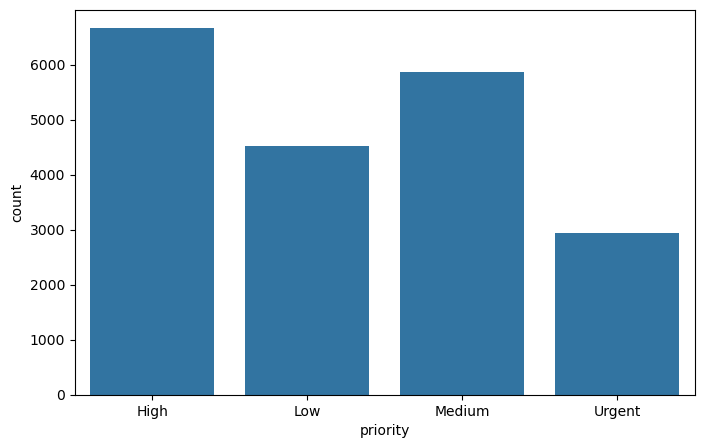

In [32]:
#Visualization
plt.figure(figsize=(8,5))


sns.countplot(data=df,x=df['priority'])


<Axes: xlabel='product', ylabel='count'>

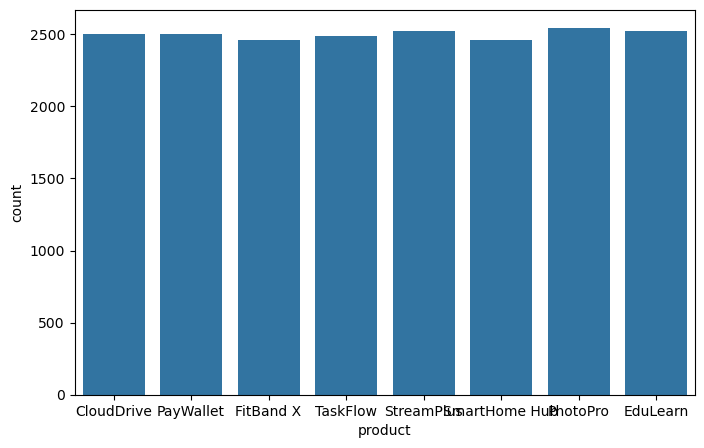

In [10]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x=df['product'])

<Axes: xlabel='channel', ylabel='priority'>

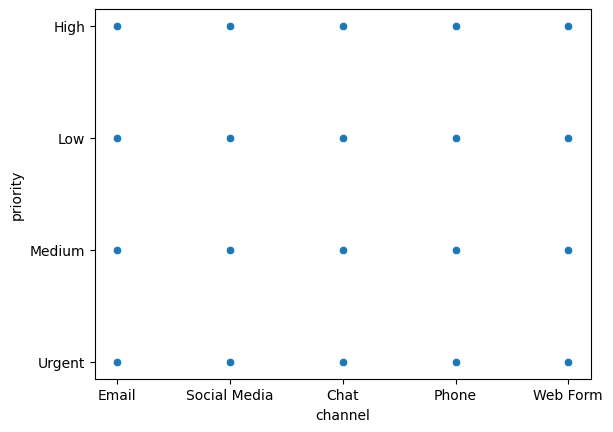

In [11]:
sns.scatterplot(data=df,y=df['priority'],x=df['channel'])

<Axes: xlabel='channel', ylabel='priority'>

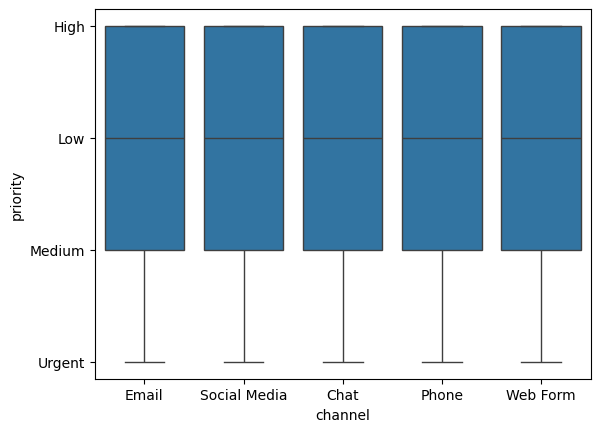

In [12]:
sns.boxplot(data=df,y=df['priority'],x=df['channel'])

<Axes: xlabel='product', ylabel='resolution_hours'>

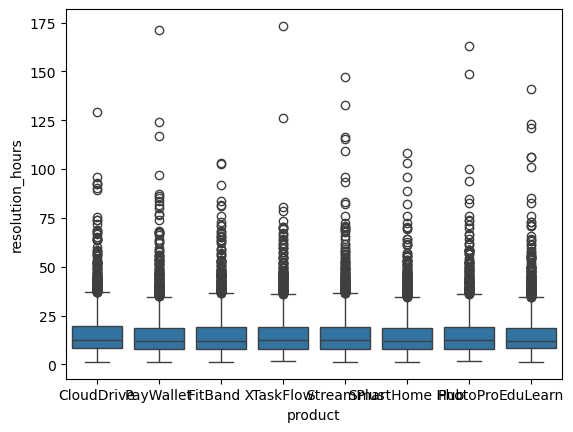

In [13]:
sns.boxplot(data=df,y=df['resolution_hours'],x=df['product'])

In [33]:
X=df['message'].fillna('').astype(str)
y=df['priority']

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [35]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16000
Testing records: 4000


In [36]:
tfidf= TfidfVectorizer(lowercase=True,stop_words='english',max_features=10000,ngram_range=(1, 2))

In [37]:
X_train_tfidf=tfidf.fit_transform(X_train)

X_test_tfidf=tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (16000, 687)
Testing matrix: (4000, 687)


In [38]:
model=LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42)
nb_model = MultinomialNB(alpha=1.0)
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=30,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

print(X.shape)
print(y.shape)

print(X.head())
print(y.value_counts())

(20000,)
(20000,)
0    Hi, Sync is not working on CloudDrive across m...
1    Hey, I love the new dark mode in PayWallet, gr...
2    Hi, My card was declined when paying for FitBa...
3    Hey, My TaskFlow account got locked after pass...
4    The FitBand X app keeps crashing when I open i...
Name: message, dtype: object
priority
High      6665
Medium    5869
Low       4525
Urgent    2941
Name: count, dtype: int64


In [39]:
model.fit(X_train_tfidf,y_train)
nb_model.fit(X_train_tfidf, y_train)
dt_model.fit(X_train_tfidf, y_train)



print("Model Training Completed")

Model Training Completed


In [40]:
#Measuring the accuracy 

y_pred=model.predict(X_test_tfidf)
nb_pred = nb_model.predict(X_test_tfidf)
dt_pred = dt_model.predict(X_test_tfidf)


In [41]:
y_pred

nb_pred

dt_pred

array(['Medium', 'Medium', 'Medium', ..., 'Medium', 'High', 'Medium'],
      shape=(4000,), dtype=object)

In [42]:
print("Accuracy-Logistic Regression:",accuracy_score(y_test,y_pred))
print("Accuracy-Naive Bayes:", accuracy_score(y_test, nb_pred))
print("Accuracy-Decission Tree:", accuracy_score(y_test, dt_pred))



Accuracy-Logistic Regression: 1.0
Accuracy-Naive Bayes: 1.0
Accuracy-Decission Tree: 0.99925


In [44]:
print("Logistic Regression");

print( classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("Naive Bayes ");

print( classification_report(
    y_test,
    nb_pred,
    zero_division=0
))


print("Decission Tree Bayes ");

print( classification_report(
    y_test,
    dt_pred,
    zero_division=0
))


Logistic Regression
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      1333
         Low       1.00      1.00      1.00       905
      Medium       1.00      1.00      1.00      1174
      Urgent       1.00      1.00      1.00       588

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000

Naive Bayes 
              precision    recall  f1-score   support

        High       1.00      1.00      1.00      1333
         Low       1.00      1.00      1.00       905
      Medium       1.00      1.00      1.00      1174
      Urgent       1.00      1.00      1.00       588

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000

Decission Tree Bayes 
              precision    recall  f1-score   support

        High       1

In [45]:
new_incident = [
    " TaskFlow not wor?"
]

# Convert text into TF-IDF features
new_incident_tfidf = tfidf.transform(new_incident)

# Predict priority
prediction = model.predict(new_incident_tfidf)

print("Predicted Incident Priority:", prediction[0])

Predicted Incident Priority: Low
